In [ ]:
# goals of this experimentation: we want to determine the energy release during a specific quantum state
# to achieve this and be able to calculate the energy we will use Hamiltonian mechanics and 
# quantum computing principles. The following steps outline the process:
# 1. Define the quantum system and its parameters
# 2. Prepare the initial quantum state
# 3. Apply the necessary quantum gates
# 4. Measure the final quantum state using Hamiltonian equation: H = JZ1Z0 + hx(X1+X0)
# 5. Analyze the results to determine the energy release

In [11]:
# imports
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
# simulator imports
from qiskit_aer import AerSimulator
# a noise model will be add to the simulator to mimic the real quantum computer, based on the selected backend
from qiskit_aer.noise import NoiseModel
from qiskit.primitives import BackendSamplerV2, BackendEstimatorV2
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import EstimatorV2 as Estimator
# to visualize the results
from qiskit.visualization import plot_histogram


from utils import get_backend



In [1]:
# set default values
counts_real = None
counts_sim = None
J=1.0 # antiferromagnetic coupling (J<0)
hx=-0.5 # transverse field strengh

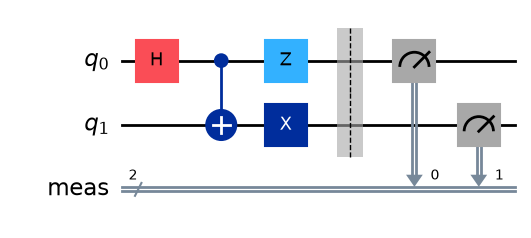

In [4]:
# |w> = 1/sqrt(2) * (|10> - |01>)
# draw circuit for |w> state; we get the circuit that simulate the map model of the problem in real life
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h(0)
quantum_circuit.cx(0, 1)
quantum_circuit.x(1) # The gate is apply on q1;it inverse q1 from 0->1 and 1->0 it does not change the state of q0
quantum_circuit.z(0) # it adds a phase of pi to the state of q0

# measure the circuit
quantum_circuit.measure_all()

# draw the circuit
quantum_circuit.draw(output='mpl')


qiskit_runtime_service.__init__:WARNING:2026-08-21 23:24:21,283: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: JulesVerneInstance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


QiskitRuntimeService exists and is accessible.


qiskit_runtime_service.__init__:WARNING:2026-08-21 23:24:28,928: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: JulesVerneInstance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-08-21 23:24:28,930: Loading instance: JulesVerneInstance, plan: open


Available backends: [<IBMBackend('ibm_fez')>, <IBMBackend('ibm_marrakesh')>, <IBMBackend('ibm_kingston')>]


qiskit_runtime_service.backends:WARNING:2026-08-21 23:24:30,508: Loading instance: JulesVerneInstance, plan: open
qiskit_runtime_service.backends:WARNING:2026-08-21 23:24:32,202: Using instance: JulesVerneInstance, plan: open


selecting backend name: ibm_fez with 156 qubits


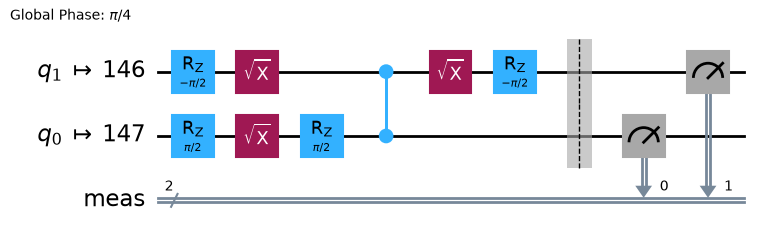

In [17]:
# get the backend and do optimization before running the circuit
backend = get_backend()
preset_pass_manager = generate_preset_pass_manager(target=backend.target, optimization_level=3)
quantum_circuit_isa = preset_pass_manager.run(quantum_circuit)
# draw the optimized circuit
quantum_circuit_isa.draw(output='mpl')

In [ ]:
# execute the circuit on the backend - real quantum computer
sampler = Sampler(mode=backend)
job = sampler.run([quantum_circuit_isa], shots=100)
results = job.result()
counts_real = results[0].data.meas.get_counts()


In [19]:
# execute the circuit on a simulator
# create a noise model based on the backend
noise_model = NoiseModel.from_backend(backend)
# create a simulator with the noise model, using Aer in SamplerV2
backend_simulator = AerSimulator(noise_model=noise_model)
sampler_simulator = BackendSamplerV2(backend=backend_simulator)
# it is also possible to create fake backend simulator and so fake sampler based on fake backend
# backend_generated = GenericBackendV2(num_qubits=18)
# sampler_generated = BackendSamplerV2(backend=backend_generated)


# get results
job_sim = sampler_simulator.run([quantum_circuit])
results_sim = job_sim.result()
counts_sim = results_sim[0].data.meas.get_counts()

Real Quantum Computer
counts =  {'01': 56, '10': 42, '00': 2}


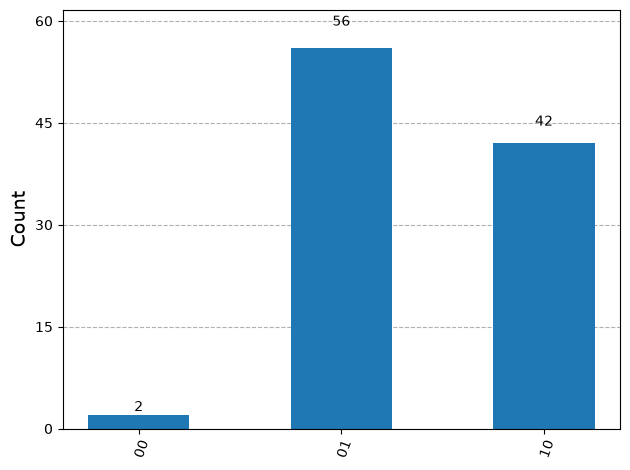

In [29]:
# display results

print("Real Quantum Computer")
print("counts = ", counts_real)
plot_histogram(counts_real) if counts_real is not None else None

Simulator Quantum Computer
counts =  {'01': 447, '10': 539, '00': 18, '11': 20}


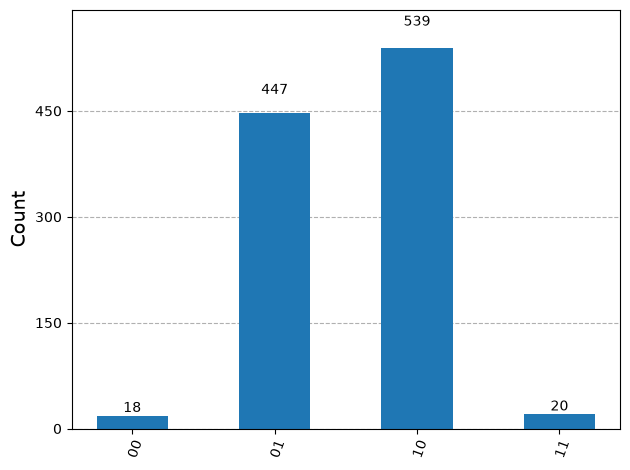

In [30]:
# display simulator results
print("Simulator Quantum Computer")
print("counts = ", counts_sim) 
plot_histogram(counts_sim) if counts_sim is not None else None

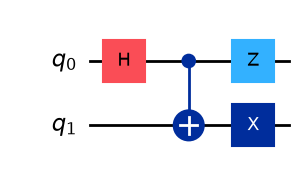

In [5]:
# Use Estimator to get the total energy in the circuit thanks to Hamiltonian formula
# Define the Hamiltonian H = J Z1 Z2 + hx (X1+X2)
observables = SparsePauliOp.from_list([("ZZ",J), ("XI",hx), ("IX", hx)])
# |w> = 1/sqrt(2) * (|10> - |01>)
# draw circuit for |w> state; we get the circuit that simulate the map model of the problem in real life
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h(0)
quantum_circuit.cx(0, 1)
quantum_circuit.x(1) # The gate is apply on q1;it inverse q1 from 0->1 and 1->0 it does not change the state of q0
quantum_circuit.z(0) # it adds a phase of pi to the state of q0

# draw the circuit
quantum_circuit.draw(output='mpl')

qiskit_runtime_service.__init__:WARNING:2026-08-27 15:05:55,225: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: JulesVerneInstance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


QiskitRuntimeService exists and is accessible.


qiskit_runtime_service.__init__:WARNING:2026-08-27 15:06:00,338: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: JulesVerneInstance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-08-27 15:06:00,340: Loading instance: JulesVerneInstance, plan: open


Available backends: [<IBMBackend('ibm_fez')>, <IBMBackend('ibm_marrakesh')>, <IBMBackend('ibm_kingston')>]


qiskit_runtime_service.backends:WARNING:2026-08-27 15:06:01,804: Loading instance: JulesVerneInstance, plan: open
qiskit_runtime_service.backends:WARNING:2026-08-27 15:06:03,334: Using instance: JulesVerneInstance, plan: open


selecting backend name: ibm_fez with 156 qubits


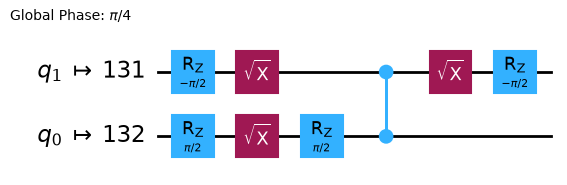

In [6]:
# get the backend and do optimization before running the circuit
backend = get_backend()
preset_pass_manager = generate_preset_pass_manager(target=backend.target, optimization_level=3)
quantum_circuit_isa = preset_pass_manager.run(quantum_circuit)
observables_isa = observables.apply_layout(layout=quantum_circuit_isa.layout)
# draw the optimized circuit
quantum_circuit_isa.draw(output='mpl')

In [9]:
estimator = Estimator(mode=backend)
pubs = [(quantum_circuit_isa, observables_isa)]
job = estimator.run(pubs)
results = job.result()
print(results[0].data.evs) # energy calculated by Estimators behind the scene

-0.99691449675112


In [15]:
# simulated version

pubs = [(quantum_circuit, observables)]
# execute the circuit on a simulator
# create a noise model based on the backend
noise_model = NoiseModel.from_backend(backend)
# create a simulator with the noise model, using Aer in SamplerV2
backend_simulator = AerSimulator(noise_model=noise_model)
estimator_simulator = BackendEstimatorV2(backend=backend_simulator)
# it is also possible to create fake backend simulator and so fake sampler based on fake backend
# backend_generated = GenericBackendV2(num_qubits=18)
# estimator_generated = BackendEstimatorV2(backend=backend_generated)


# get results
job_sim = estimator_simulator.run(pubs)
#print(f"{job_sim.result()=}")
results_sim = job_sim.result()

print(results_sim[0].data.evs) # energy calculated by Estimators behind the scene

-0.935791015625
